# Text Analysis: An Introduction

In this workshop, you will learn some basic techniques for text analysis of literature. You will start out by learning how to represent a corpus of texts in the "tidy text" format. Then you will perform word-frequency analysis, word-sequence analysis and finally sentiment analysis on the corpus.

This workshop presupposes that you already know Python's basic syntax, and have some familiary with [pandas](https://pandas.pydata.org).

## Load Necessary Software

Before we begin, run the cells below to load the necessary software, and download key datasets for use with NLTK (the Natural Language ToolKit).

In [ ]:
import nltk                  # For sentiment analysis
import nltk.sentiment        #
import pandas as pd          # For data manipulation
import seaborn.objects as so # For data visualisation
from tqdm import tqdm        # For progress bars
tqdm.pandas()

from corpus import import_corpus

In [ ]:
nltk.download(["punkt", "punkt_tab", "vader_lexicon"], download_dir="nltk_data")

## What Can Text Analysis Do?

Text analysis allows the researcher to find statistical patterns in language. The text is 'tokenised' (broken into pieces), then the 'tokens' can be sequenced, counted and modelled. Text analysis relies on a strong complementarity between humans and computers.

Humans are very good at understanding texts. When we humans interpret texts, we develop rich, deep, abstract models of them. We call these models 'interpretations', and can discuss them with our friends and colleagues. Our interpretations necessarily lack detail. Most of the time, we do not memorise all the words of a text; even if we *do* memorise all the words (e.g. of a short poem), we do not think about all the words every time we recall the poem. The words are memerly evidence for the interpretation.

Computers can complement humans by being extremely detailed. A computer can easily retain all the words of many books in its memory, and quickly query them. A modern Large Language Model such as GPT-5 can effectively retain about 100,000 'tokens' in its memory, far more than a human can.<sup>†</sup> The simpler token-sequence models that we will use in this workshop can retain an effectively infinite number of 'tokens' in active memory, but of course cannot produce sophisticated outputs on their own, as LLMs can.

The main point is this: in text analysis, the computer serves as an extension to human memory. It effectively allows us to recall texts in incredible detail, producing new evidence for our interpretations.

In this workshop, we will take inspiration from the American novelist Kurt Vonnegut, who imagined that a computer could be used to detect emotional language in novels, and draw graphs of their plots. Remarkably, it is possible to draw just such plots using a very simple computational technique, lexicon-based sentiment analysis.

<sup>†</sup>*LLMs are often advertised as having far larger 'context windows' than 100,000. But their output typically drops in quality if more than 100,000 words are passed into the model as input.*

In [ ]:
from IPython.display import IFrame
IFrame(src="https://www.youtube.com/embed/oP3c1h8v2ZQ?si=Nj-dhPMtRNeL2-vO", width=560, height=315)

## Part 1: Import the corpus, and convert to 'tidy text' format

For this workshop, we will analyse a small corpus from Project Gutenberg. It includes the four most-downloaded books on Gutenberg (*Frankenstein*, *Alice in Wonderland*, *Moby Dick* and *Pride and Prejudice*), plus the most famous work of Spanish literature, *Don Quixote*, in English translation.

![The five novels in the corpus](img/book-covers.png)

Code to import the novel has been provided in the [corpus.py](corpus.py) module. If you know Python, and would like to see how it works, do take a look at the code.

In [ ]:
corpus = import_corpus(
    corpus_dir="data",    # The books are in the data/ directory
    tokenise_by="word",   # Split each book into individual words
    clean_gutenberg=True, # Remove gutenberg licence from start and end
    to_lower=True         # Put all words in lower case
)

The `import_corpus` function imports the corpus into a [pandas DataFrame](https://pandas.pydata.org/pandas-docs/stable/user_guide/basics.html#basics). At first, there is one line per text. In the **tokens** column, there is a `list` of all the words in that novel:

In [ ]:
corpus

To make the data easier to use, we will reformat it into the "[tidy text format](https://www.tidytextmining.com/tidytext)" pioneered by Julia Silge and David Robinson. In this format, there is one row of the data frame per token per text. There are 1 030 334 words in our corpus, so there will be 1 030 334 rows in the "tidy" data frame.

In [ ]:
def to_tidy_text(corpus: pd.DataFrame, token_type: str="word") -> pd.DataFrame:
    """Convert `corpus` to tidy text format."""
    corpus = corpus.explode("tokens")
    corpus = corpus.reset_index(names="novel_index")
    corpus = corpus.assign(**{
        f"{token_type}_index":corpus.groupby("title").cumcount()
    })
    return corpus

In [ ]:
tidy_corpus = to_tidy_text(corpus)
tidy_corpus

## Part 2: Sequence Analysis

It can be interesting to see when a particular word appears in a novel. Using the [the `.query()` method](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.query.html), we can filter the data frame by word.

In [ ]:
tidy_corpus.query("tokens == 'fool'")

It is hard to compare the novels by looking at a table like this. It is easier to compare the novels if we compare them on a dashplot.

In [ ]:
plot = so.Plot(
    data = tidy_corpus.query("tokens == 'fool'"),
    x = "word_index",
    y = "title"
)
plot = plot.add(so.Dash(), orient="y")
plot = plot.label(title = "The word 'fool' in the corpus.")
display(plot)

This plot is ambiguous, because it doesn't indicate the length of each book. Is *Moby Dick* shorter than *Don Quixote*, or does the word "fool" simply not appear at the end of that novel? One solution is to turn **word_index** column into a percentage.

In [ ]:
def add_relative_word_index(tidy_corpus):
    """Add or replace `relative_word_index` column to `tidy_corpus`, assuming there
    is alreay a `word_index` column, and each novel has a unique `novel_index`."""

    num_words = tidy_corpus.groupby("novel_index")["word_index"].transform("max") # Number of words in each novel
    relative_word_index = tidy_corpus["word_index"] / num_words

    tidy_corpus = tidy_corpus.assign(relative_word_index = relative_word_index)

    return tidy_corpus

tidy_corpus = add_relative_word_index(tidy_corpus)
display(tidy_corpus)

In [ ]:
plot = (
    so.Plot(
        data = tidy_corpus.query("tokens == 'fool'"),
        x = "relative_word_index",
        y = "title"
    )
    .add(so.Dash(), orient="y")
    .label(title = "The word 'fool' in the corpus.")
)
display(plot)

### Exercise 1: Write a function to visualise any word across the five novels

Complete the function below, which will generate a sequence dashplot for any word in the corpus.

I have already done the first part for you: using the `word` parameter to filter the data frame. This requires the `@` notation supported by [the `.query()` method](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.query.html). I've also done the tricky final step, of using the passed `word` to give the plot a title.

You need to:

1. Set the `x` and `y` variables for the plot
2. Add in the `so.Dash()` layer, with the argument `orient="y"` so that the dashes are drawn the right way up.

In [ ]:
def visualise_word_sequence(tidy_corpus: pd.DataFrame, word: str) -> so.Plot:
    """Show how `word` is distrbuted in the novels in `tidy_corpus`.

    `tidy_corpus`: A tidy-text dataframe with "title", "tokens" and "relative_word_index" columns; tokenised by word.
    `word`:        A string; the word to look for.
    """

    plot = so.Plot(
        data = tidy_corpus.query("tokens == @word"),
        # Now set the `x` and `y` variables for the plot
        # START OF YOUR CODE
        
        # END OF YOUR CODE
    )
    # Now add the 'dash' layer; don't forget to set `orient="y"`
    # START OF YOUR CODE
    
    # END OF YOUR CODE

    # Now set the title using `.label()`
    plot = plot.label(title = f"The word '{word}' in the corpus.")

    return plot

In [ ]:
sequence_dashplot = visualise_word_sequence(tidy_corpus, word="lady")
display(sequence_dashplot)

# tests
assert isinstance(sequence_dashplot, so.Plot)
assert sequence_dashplot._data.source_vars["x"] == "relative_word_index" # Correct x?
assert sequence_dashplot._data.source_vars["y"] == "title" # Correct y?
assert len(sequence_dashplot._layers) == 1 # Did you add exactly 1 layer?
assert isinstance(sequence_dashplot._layers[0]["mark"], so.Dash) # Did you add a so.Dash?
assert sequence_dashplot._layers[0]["orient"] == "y" # Did you remember `orient = "y"`?
print("\nAll tests passed!")

**Expected output:**

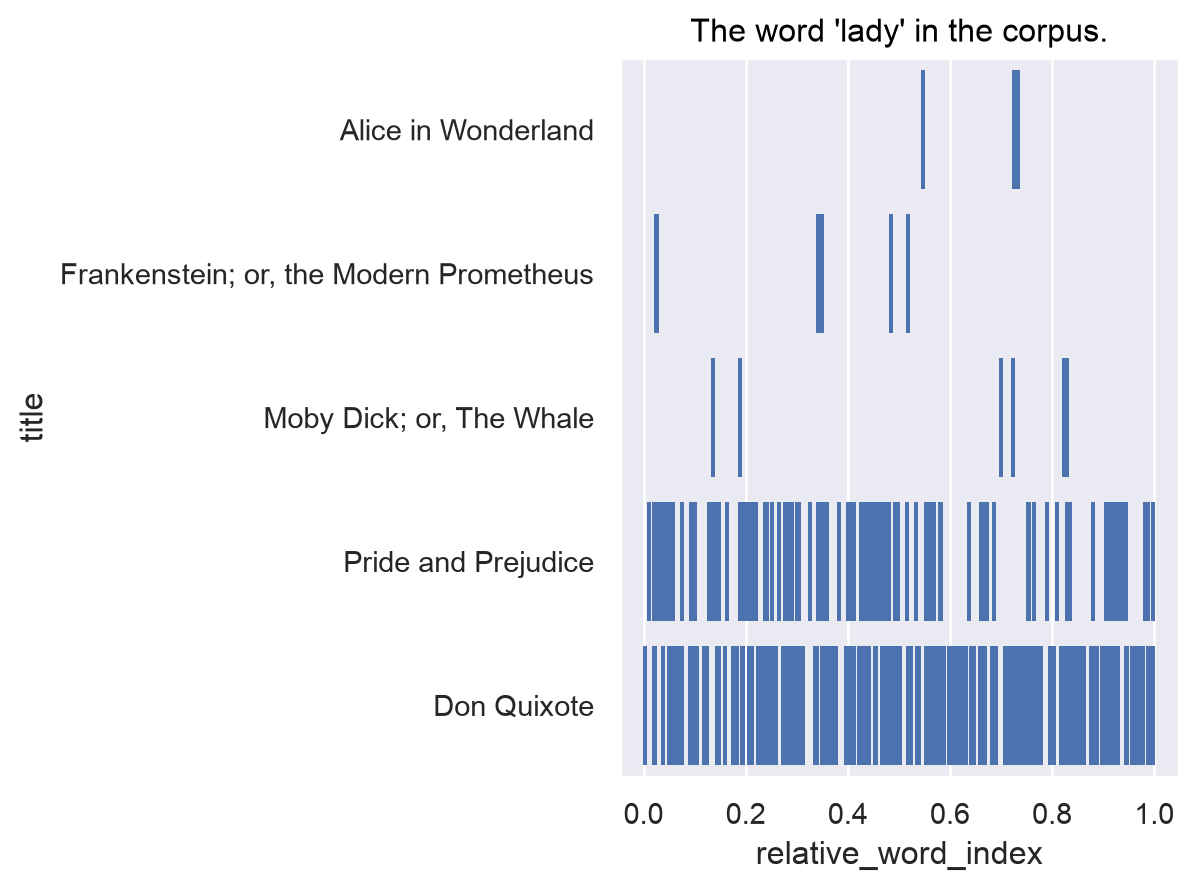

### Exercise 2: Improve the appearance of your plot

If you finish Exercise 1, you should try to improve the appearnace of your dashplot. There are no strict tests here – you just need to give it a go! The two methods you will use are:

- [the `.layout()` method](https://seaborn.pydata.org/generated/seaborn.objects.Plot.layout.html): to change the size and shape of the plot
- [the `.label()` method](https://seaborn.pydata.org/generated/seaborn.objects.Plot.label.html): to change the axis labels, or the title of the plot if you like

In [ ]:
def customise_dashplot(plot):
    """Improve the appearance of the given `sequence_dashplot`."""

    # Try changing the size of the plot, by changing the numbers. Can you work
    # out how to make the plot wider?
    plot = plot.layout(
        # Try size=(6,4) to start with
        # START OF YOUR CODE
        
        # END OF YOUR CODE
    )

    # Try improving the axis labels. What would help the reader understand?
    plot = plot.label(
        # Try x="Progress through story". How would you set the y-label?
        # START OF YOUR CODE
        
        # END OF YOUR CODE
    )
    
    return plot

In [ ]:
house_dashplot = visualise_word_sequence(tidy_corpus, "house")
house_dashplot = customise_dashplot(house_dashplot)
display(house_dashplot)

# Tests just see if you've changed the values, and haven't broken anything
assert isinstance(house_dashplot, so.Plot)
if "figsize" not in house_dashplot._figure_spec:
    print("Try changing the size of the plot. `plot = plot.layout(size=(6,4))` is a good starting point")
if "x" not in house_dashplot._labels:
    print("Did you try `plot = plot.label(x='Progress through story')`?")
if "y" not in house_dashplot._labels:
    print("Did you try setting a `y`-label?")
print("\nAll tests passed!")

**Suggested Output (Yours might be different!):**

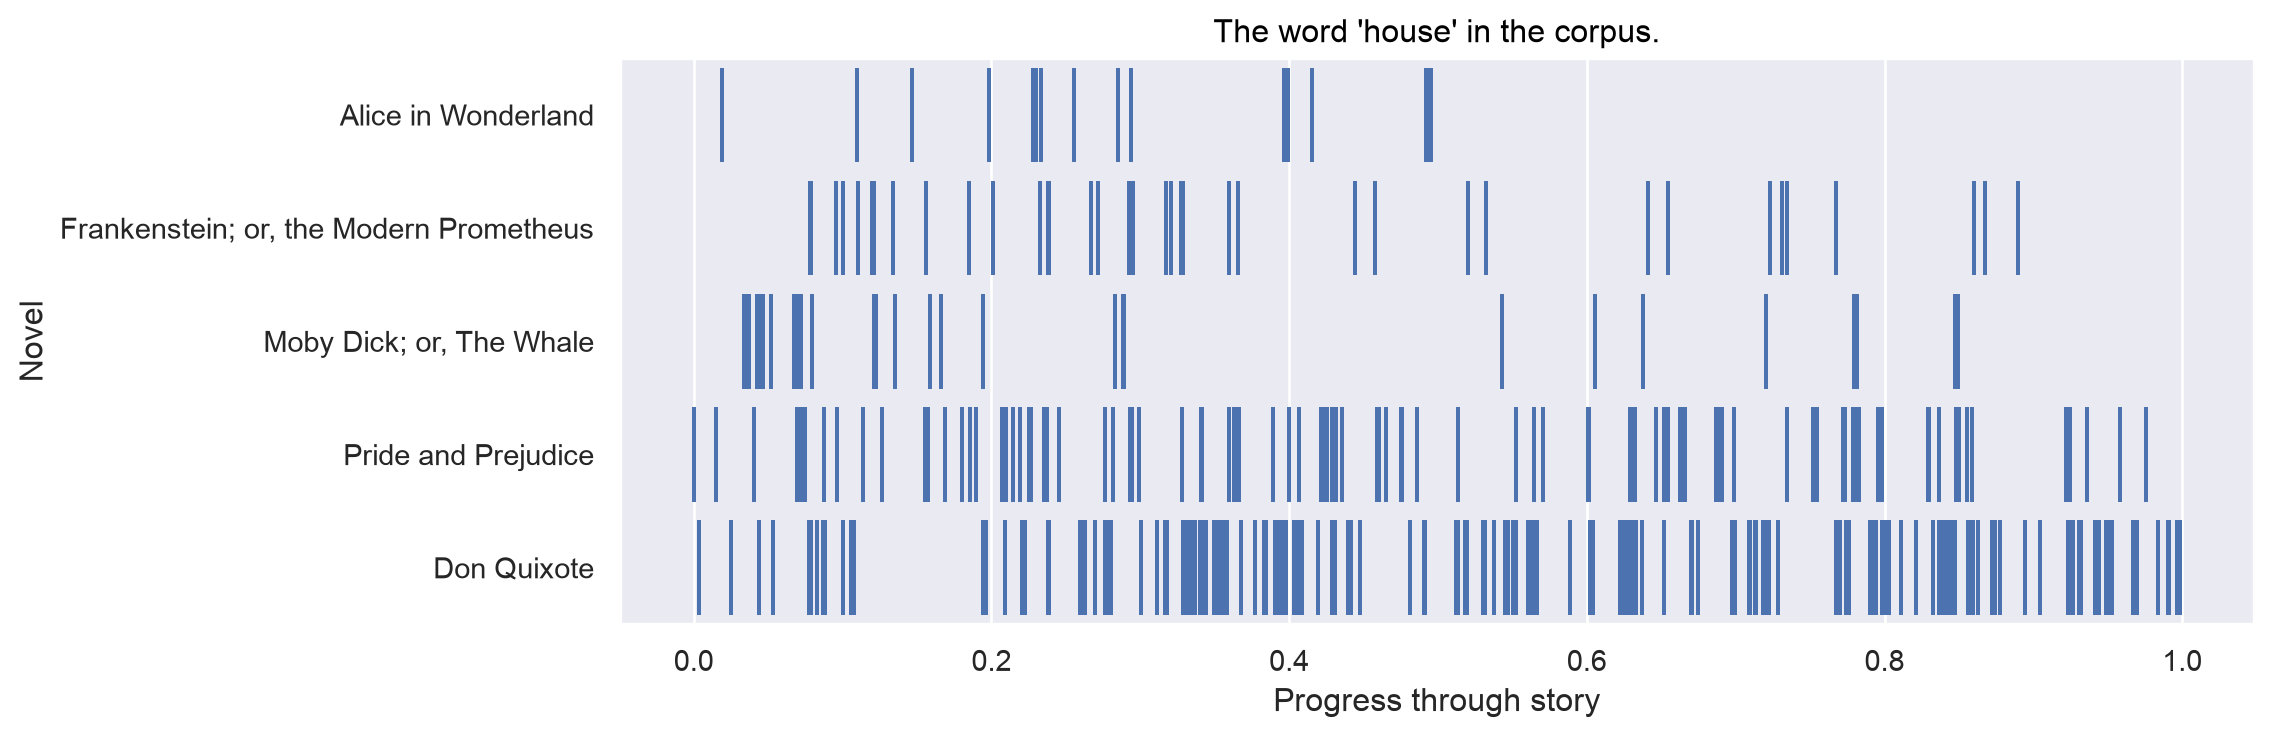

In [ ]:
# Try some more words!
your_dashplot = visualise_word_sequence(tidy_corpus, "word")
your_dashplot = customise_dashplot(your_dashplot)
display(your_dashplot)

### Discussion

1. What does the sequence analysis tell us about these novels?
2. Do the dashplots make you curious? What new research questions come into your mind when you look at them?

You can use the cell below to write some of your ideas.

---

In [ ]:
# START OF YOUR CODE

# END OF YOUR CODE

## Part 3: Sentiment Analysis

Using sentiment analysis, we can draw story arcs, just like in Kurt Vonnegut's lecture. In my book, [*Romanticism and the Contingent Self*](https://link.springer.com/book/10.1007/978-3-031-49959-3), I use this approach to compare four Romantic-era biographies:

![story arcs of four Romantic biographies, using 4 sentiment lexicons](img/figure_6_1.png)

As you can see from this figure, the results are remarkably consistent when used in this application. Four different "sentiment lexicons" (bing, afinn, syuzhet and VADER) all generate remarkably similar story arcs for each biography.

This story arcs can allow us to make interesting comparisons between texts. But they should also be validated by close reading. Does the visualised story arc actually match the story of the book? In *Romanticism and the Contingent Self*, I was especially interested in Thomas Moore's *Byron*, so included a chart linking the story arc to key moments from the book, comparing it to another biography of Lord Byron written by a rival biographer.

![Annotated plot of Moore's *Byron*](img/figure_6_2.png)

In this part of the workshop, we will perform sentiment anlaysis using [VADER](https://ojs.aaai.org/index.php/ICWSM/article/view/14550).

### The VADER lexicon

VADER is a "Dictionary", because it relies on a dictionary (or "lexicon") of words to determine the score of a sentence. The reseachers constructed the dictionary using [Amazon Mechanical Turk](https://www.mturk.com/), a micro-work site where workers could earn small amounts of money for answering questionnaires.

You can see the VADER lexicon by accessing the `.lexicon` property of the `SentimentIntensityAnalyzer` object. This `.lexicon` is simply a Python `dict`, where the keys are the words in the lexion, and the values are the scores.

In [ ]:
analyzer = nltk.sentiment.SentimentIntensityAnalyzer()

lexicon_df = pd.DataFrame(analyzer.lexicon.items()).rename({0:"word", 1:"sentiment"}, axis="columns")
lexicon_df

In [ ]:
lexicon_df.iloc[5000:5010]

### Applying VADER to a text

You can can calculate the scores for a sentence using the `.polarity_scores()` method:

In [ ]:
analyzer = nltk.sentiment.vader.SentimentIntensityAnalyzer()
analyzer.polarity_scores("""
    She loves you! Yeah! Yeah! Yeah!
    She loves you! Yeah! Yeah! Yeah!
""")

In [ ]:
analyzer.polarity_scores("""
    I've never seen a diamond in the flesh
    I cut my teeth on wedding rings in the movies
    And I'm not proud of my address
    In a torn-up town, no postcode envy
""")

It returns a `dict` of four scores, for negative sentiments (`"neg"`), neutral sentiments (`"neu"`), positive sentiments (`"pos"`) and an overall `"compound"` score.

To calculate these scores, it scans every word in the sentence, and replaces it with its score in the lexicon. All words in the lexicon have either a positive or negative score—any words *not* in the lexicon are considered "neutral". Because it is "Valence Aware", VADER modifies the score for each word according to some hard-coded rules. For example, capital letters, "boosters" and negation all make a difference:

In [ ]:
analyzer.polarity_scores("I am unhappy")

In [ ]:
analyzer.polarity_scores("I am UNHAPPY!") # Caps + Exclamation

In [ ]:
analyzer.polarity_scores("I am unhappy!") # Exclamation

In [ ]:
analyzer.polarity_scores("I am not unhappy") # Negation

In [ ]:
analyzer.polarity_scores("I am NOT unhappy") # Capital NOT makes no difference

Once the sentiments have been calculated for each word, VADER uses slightly complicated formulae to determine the `"compound"` score. The basic idea is that it subtracts the `"neg"` score from the `"pos"` score, ignoring the `"neu"` score. Then it applies a formula to scale the `"compound"` score to a common standard.

It uses the following formula:

$$
compound = \frac{sum(pos) + sum(neg)}{\sqrt{(sum(pos) + sum(neg))^2 + 15}}
$$

For the `"compound"` index, the negative scores are treated as negative numbers. So if the negative sentiments outweigh the positive, then $total(pos) + total(neg)$ will be less than $0$. This $15$ was found by VADER's developers to be the "expected maximum" score. Basically the formula squashes any scores higher than $15$ or lower than $-15$. Basically if the combined sentiments of a text are $15$ or greater, then the score will be approximately $1$. If the combined senitments of a text are $-15$ or lower, then the score will be approximately $-1$.

If you'd like to get a sense of how the normalisation function works, here it is, copied-and-pasted from the NLTK source code. Try putting in some different values to see how it reduces scores to fit within the range $-1 \le x \le 1$. You can try changing `alpha`, to get a sense of what "expected maximum value" means.

In [ ]:
import math

def normalize(score, alpha=15):
    """
    Normalize the score to be between -1 and 1 using an alpha that
    approximates the max expected value
    """
    norm_score = score / math.sqrt((score * score) + alpha)
    return norm_score

In [ ]:
normalize(-15)

#### Exercise 3: Can a computer help us 'interpret' text?

Find a song or article that you like (in English), and paste it into the cell below. Run the cell to see how VADER scores the text. If you want to analyse VADER's scores, you can use the following cell to look up words in the VADER lexicon.

When you have looked at the results, discuss:

1. Can VADER reliably detect the emotions in a text?
2. What are the strengths and weaknesses in the lexicon-based approach?

In [ ]:
analyzer = nltk.sentiment.vader.SentimentIntensityAnalyzer()
analyzer.polarity_scores(
    # YOUR TEXT BELOW: in between the triple quotation marks
    """
    
    """
)

In [ ]:
analyzer.lexicon["yeah"]

---

YOUR ANSWER HERE

### Generating story arcs

To generate story arcs for the corpus, we need to split each novel into sentences, and then apply the `.polarity_scores()` method to each sentence. Execute the two cells below to import the corpus as sentences, and then apply sentiment analysis.

In [ ]:
def import_sentence_corpus(verbose=2):
    """Re-import the corpus, but tokenised by sentence instead of by word."""
    corpus = import_corpus("data", tokenise_by="sent", verbose=verbose)
    corpus = corpus.explode("tokens")
    corpus = corpus.reset_index(names="novel_index")
    corpus = corpus.assign(sentence_index = corpus.groupby("novel_index").cumcount())
    return corpus

sentence_corpus = import_sentence_corpus()
display(sentence_corpus)

In [ ]:
def calculate_sentiment_scores(corpus):
    """Given a `corpus` of texts, tokenised by sentence, calculate the sentiment scores
    for each sentence using the VADER sentiment analysis algorithm."""

    analyzer = nltk.sentiment.SentimentIntensityAnalyzer()

    # Get polarity scores for every sentence using .progress_map() on "tokens"
    polarity_scores = corpus["tokens"].progress_map(analyzer.polarity_scores)

    # Create a data frame of the sentiment scores using pd.json_normalize
    polarity_scores_df = pd.json_normalize(polarity_scores)

    # Concatenate the sentiment scores onto `corpus`
    corpus = pd.concat([corpus, polarity_scores_df], axis="columns")

    # Return the corpus (which now has four new columns)
    return corpus

sentence_corpus = import_sentence_corpus(verbose=0)
sentence_corpus = calculate_sentiment_scores(sentence_corpus)
display(sentence_corpus)

Now that we have the sentiment scores, we can try to visualise the novels as story arcs. But there is a problem...

In [ ]:
def plot_sentiment_arcs(sentiment_data):
    """Plot the sentiment arcs of the different titles in `sentiment_data`, using
    a facetted line graph."""

    plot = so.Plot(data=sentiment_data, x="sentence_index", y="compound")
    plot = plot.add(so.Line())
    plot = plot.facet(row="title", wrap=2)
    return plot

plot = plot_sentiment_arcs(sentence_corpus)
display(plot)

The data is extremely noisy. From sentence to sentence, the sentiment scores vary wildly. To see the shape of each story, we need to 'smooth' the plot. One way to do this is with a rolling mean.

In [ ]:
def plot_sentiment_arcs_rollmean(sentiment_data, window_size=5):
    """Plot the sentiment arcs of the different titles in `sentiment_data`, using
    a facetted line graph. Smooth the compound scores with a rolling average of the
    given `window_size`."""

    # Smooth the data
    sentiment_data = sentiment_data.assign(
        compound_rollmean = sentiment_data["compound"].rolling(window=window_size, center=True).mean()
    )
    # Show on facetted lineplot
    plot = so.Plot(data=sentiment_data, x="sentence_index", y="compound_rollmean")
    plot = plot.add(so.Line())
    plot = plot.facet(row="title", wrap=2)
    return plot

In [ ]:
plot = plot_sentiment_arcs_rollmean(sentence_corpus, window_size=50)
display(plot)

We can also [fit a polynomial](https://en.wikipedia.org/wiki/Polynomial_regression) to the data, using a statistical transformation built into seaborn.

In [ ]:
def fit_polynomial_to_plot(plot, order=2):
    """Fit a polynomial of given `order` to the passed `plot`."""
    plot = plot.add(so.Line(color="red"), so.PolyFit(order=order), y="compound")
    return plot

In [ ]:
plot = plot_sentiment_arcs_rollmean(sentence_corpus, window_size=50)
plot = fit_polynomial_to_plot(plot, order=3)
display(plot)

As with the earlier sequence analysis, we also need to choose how we would like the x-axis to appear. Do we want the plot to show the length of each novel? Or would we like to normalise the lengths, so that the lengths are ignored for the sake of analysis?

In [ ]:
def free_x_axis(plot):
    """'Free' the x-axis, so that the length of each novel is ignored
    on the plot."""
    plot = plot.share(x=False)
    return plot

In [ ]:
plot = plot_sentiment_arcs_rollmean(sentence_corpus, window_size=50)
plot = fit_polynomial_to_plot(plot, order=3)
plot = free_x_axis(plot)
display(plot)

### Exercise 4: Experiment to create the most informative plot

In the cell below, experiment with the `window_size`, `order`, `share_x`, `height` and `width` parameters until you have created a plot that you are happy with.

When you are done, discuss:

1. How did you decide the best settings for each parameter? What makes a story arc plot good or bad?
2. If you were using this technique in your own research, how would you validate the analysis?

In [ ]:
def build_story_arc_plot(
    sentiment_data: pd.DataFrame, # The corpus of novels, with sentiment scores
    window_size: int,     # Window size for the rolling mean
    order: int,           # Order parameter for the polynomial
    share_x: bool,        # True = same x-axis for all subplots; False = ignore length of novels
    height: int=4,        # Height of plot
    width: int=6          # Width of plot
) -> so.Plot:
    """Build story arcs of the novels in `corpus`."""
    # Smooth the data
    sentiment_data = sentiment_data.assign(
        compound_rollmean = sentiment_data["compound"].rolling(window=window_size, center=True).mean()
    )
    # Show on facetted lineplot
    plot = so.Plot(data=sentiment_data, x="sentence_index") # Defaults layer
    plot = plot.add(so.Line(), y="compound_rollmean") # Rolling average
    plot = plot.add(so.Line(color="red"), so.PolyFit(order=order), y="compound") # Fitted curve
    plot = plot.label(
        x = "Sentence",
        y = f"Smoothed VADER (w={window_size}; o={order})"
    )
    plot = plot.facet(row="title", wrap=2) # One plot per novel
    plot = plot.share(x=share_x)
    plot = plot.layout(size=(width, height))
    return plot

In [ ]:
plot = build_story_arc_plot(
    sentiment_data=sentence_corpus,
    # Choose a window_size, order, share_x, width, height
    # START OF YOUR CODE
    
    # END OF YOUR CODE
)
display(plot)

**Possible Output (yours can be different!)**

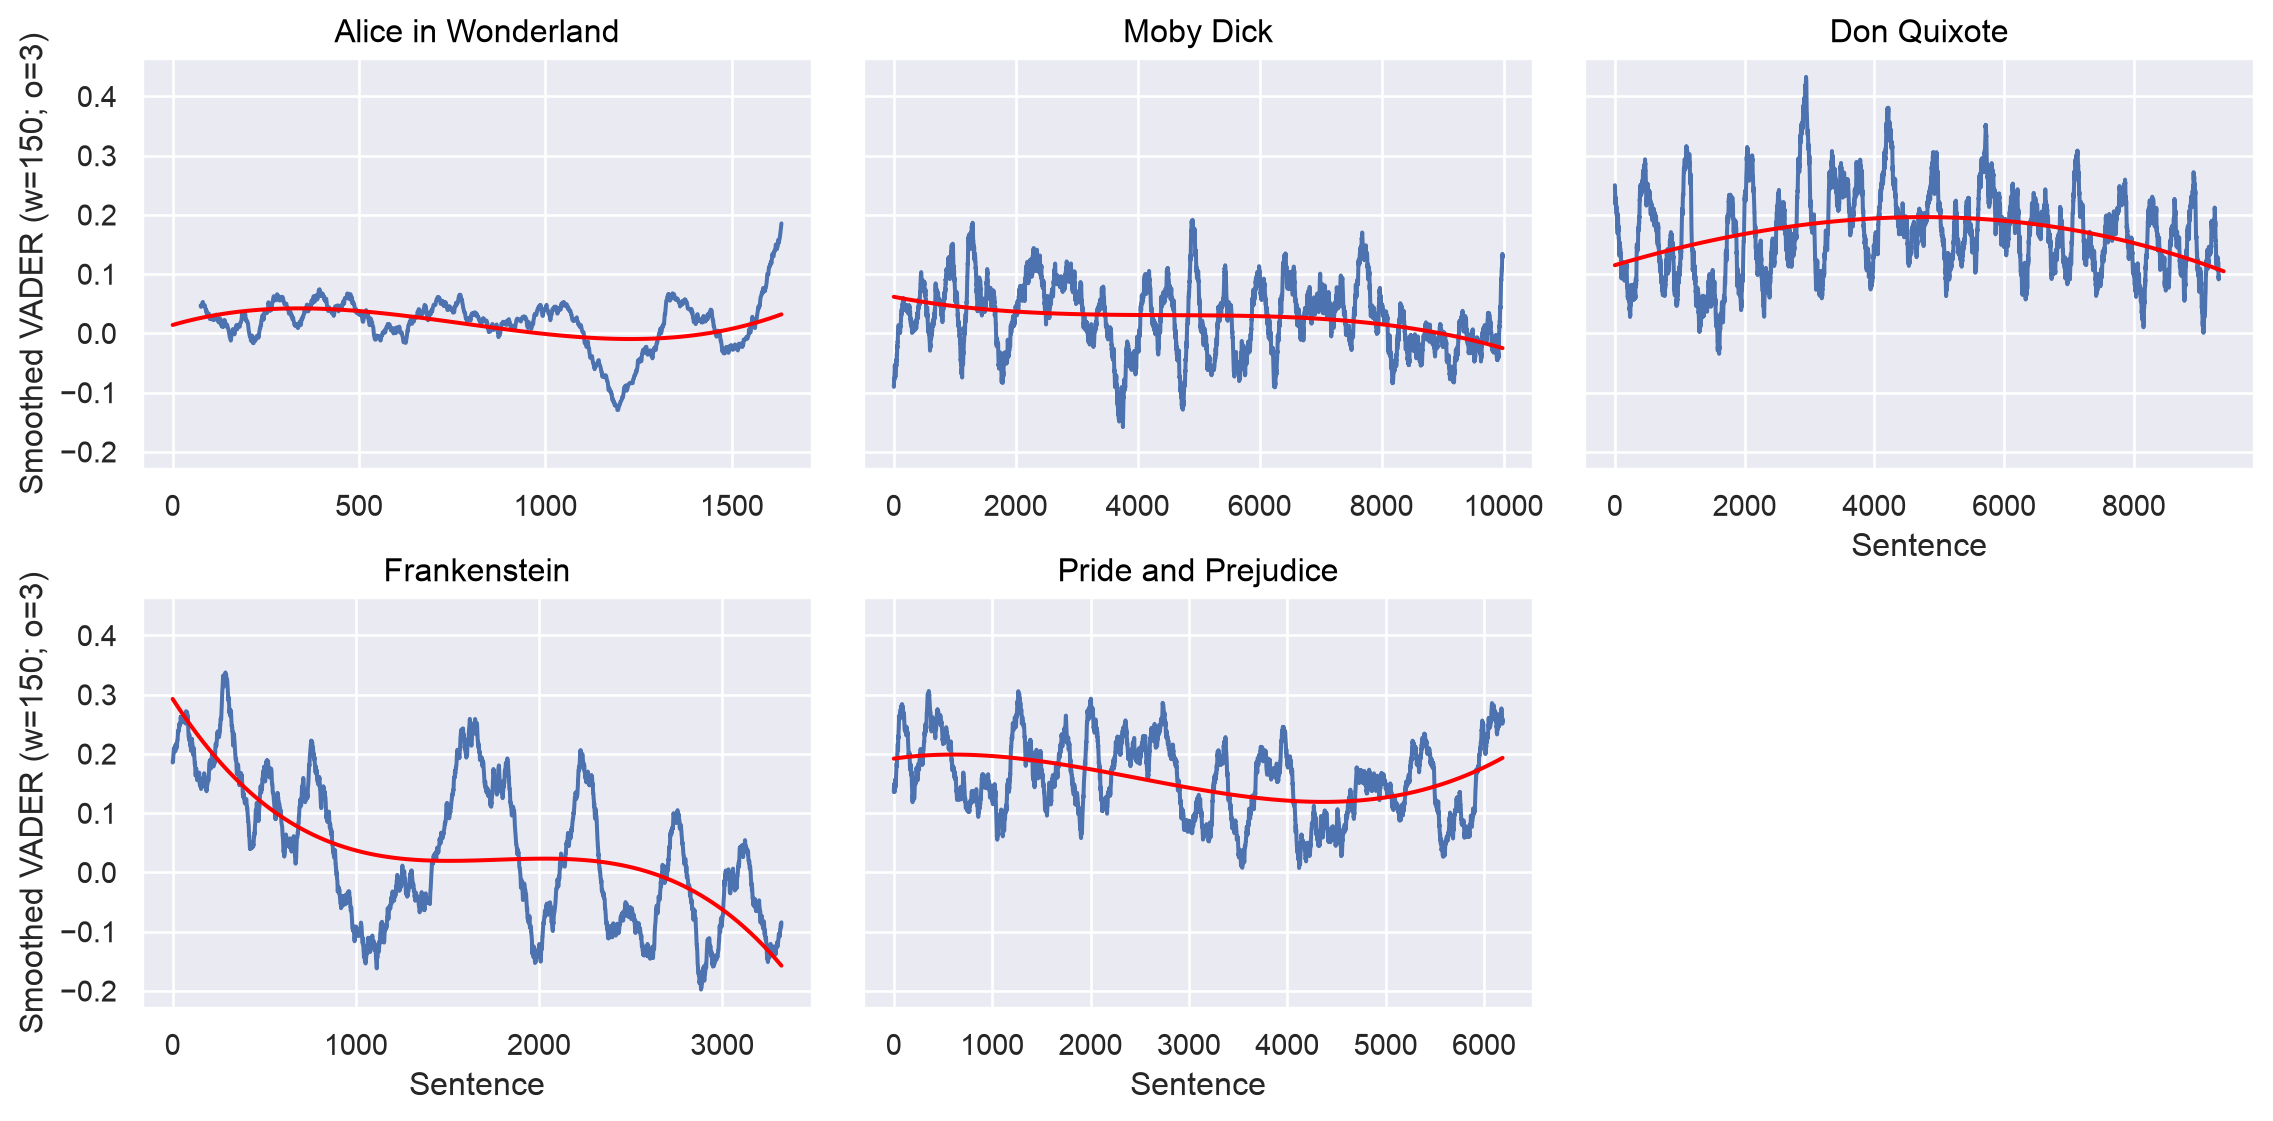

---

YOUR ANSWER HERE

## Part 4: Word Frequency Analysis

So far, we have been considering each novel as a *sequence of words*. In this model of text, we know *which words* appear in *which order*. Many text analysis approaches use an even simpler model of text: the *bag of words*. In a *bag of words* model, which know *which words* are in a text, but do not know *which order* they are in.

The bag of words approach can be surprisingly useful. Sometimes, patterns in data can be hard to see if we are paying attention to too many different aspects of the data. If we forget an aspect of the data (e.g. the order of the words), then we can sometimes see patterns in the remaining data.

In [ ]:
def get_bag_of_words():
    """Import corpus, tokenise by word, tidy and return the bag of words."""
    corpus = import_corpus(corpus_dir="data", tokenise_by="word", clean_gutenberg=True, to_lower=True, verbose=1)
    corpus = corpus.explode("tokens")
    corpus = corpus.reset_index(names="novel_index")
    corpus = corpus.assign(word_index = corpus.groupby("novel_index").cumcount())
    # Now count the words in each novel
    bag_of_words = corpus.groupby(["novel_index", "title", "date", "tokens"]).size()
    bag_of_words = bag_of_words.to_frame(name="frequency").reset_index()
    # Now get the total words for each novel
    bag_of_words = bag_of_words.assign(
        word_count=bag_of_words.groupby("title")["frequency"].transform(sum)
    )
    # Now relative frequencies
    bag_of_words = bag_of_words.assign(
        relative_frequency=bag_of_words["frequency"] / bag_of_words["word_count"] * 1000
    )
    return bag_of_words

bag_of_words = get_bag_of_words()
display(bag_of_words)

Now we can investigate particular keywords using `.query()`:

In [ ]:
words = ["she", "her", "he", "him"]
bag_of_words.query("tokens in @words")

A bar chart is a good option for displaying this data:

In [ ]:
def plot_word_frequencies(bag_of_words: pd.DataFrame, words: list|set|tuple):
    """Plot the relative frequencies of `words` in the `bag_of_words` for
    each novel."""
    filtered_data = bag_of_words.query("tokens in @words")
    plot = so.Plot(
        data=filtered_data,
        x="tokens",
        y="relative_frequency",
        color="title"
    )
    plot = plot.add(so.Bar(), so.Dodge())
    plot = plot.label(
        x="Word",
        y="Frequency (per 1000 words)",
        color="Novel"
    )
    return plot

In [ ]:
plot_word_frequencies(bag_of_words, ("he", "him", "she", "her"))

### Exercise 5: Explore the vocabulary of the novels

In the cell below try plotting some different words in the novels. Then discuss:

1. What can word frequency analysis tell us about literary works?
2. What are the advantages and disadvantages of the 'bag of words', compare to sequence models?

In [ ]:
freq_plot = plot_word_frequencies(
    bag_of_words=bag_of_words,
    # Choose 3-5 words of your own to explore:
    # START OF YOUR CODE
    
    # END OF YOUR CODE
)
display(freq_plot)

---

YOUR ANSWER HERE

## Conclusion

I hope you enjoyed this workshop. If you'd like to explore text anlaysis further, I would recommend the following free books:

- Melanie Walsh, [*Introduction to Cultural Analytics in Python*](https://melaniewalsh.github.io/Intro-Cultural-Analytics/welcome.html)
- Julia Silge and David Robinson, [*Text Mining with R: A Tidy Approach*](https://www.tidytextmining.com/)